# TP3 - Optimización de Modelos de Machine Learning

**Grupo:** 2

En este trabajo práctico se aborda un problema de **clasificación supervisada**: predecir si una reserva de infraestructura GPU será cancelada antes de su ejecución.



In [21]:
# IMPORTS

import pandas as pd
# pandas sirve para trabajar con datos en forma de tablas (DataFrames).

import numpy as np
import matplotlib.pyplot as plt

# Para que pandas muestre todas las columnas al imprimir un DataFrame
pd.set_option("display.max_columns", None)

## 1. Descripción del dataset

### 1.1 Contexto

El dataset contiene información sobre **reservas de GPUs** en una plataforma de cómputo.

Una **GPU** es un procesador especializado en realizar muchos cálculos en paralelo, muy utilizado para entrenar modelos de machine learning. Como son costosas, muchos usuarios no las compran sino que las alquilan por horas a plataformas que disponen de muchas GPUs conectadas entre sí.

Cada fila del dataset representa **una reserva**: un cliente solicita cierta cantidad y tipo de GPUs, para una fecha determinada y durante una cantidad de horas. Antes de esa fecha, el cliente puede cancelar la reserva. Predecir qué reservas se van a cancelar le permite a la plataforma reasignar esos recursos a otros clientes y evitar que queden sin uso.

La información disponible puede agruparse en:

- **Características temporales:** cuándo se programó la ejecución y con cuánta anticipación se hizo la reserva.
- **Recursos solicitados:** horas GPU, procesos, tipo de GPU y almacenamiento.
- **Historial del cliente:** si ya usó la plataforma y cuántas reservas canceló o completó antes.
- **Características económicas y contractuales:** costo por hora y tipo de compromiso.

La variable objetivo es `canceled_job`, que indica si la reserva fue cancelada (1) o no (0).

Predecir cancelaciones con anticipación permitiría a la plataforma planificar mejor la capacidad de cómputo, por ejemplo reasignando recursos o aplicando sobreventa controlada.

In [22]:
# CARGA DEL DATASET

# El CSV está en la carpeta data/, dentro del repo
df = pd.read_csv("data/gpu_resource_reservations.csv")

print("Filas:", df.shape[0])
print("Columnas:", df.shape[1])

df.head()

Filas: 47842
Columnas: 34


,canceled_job,hours_before_execution,execution_year,execution_month,execution_week,execution_day,peak_gpu_hours,offpeak_gpu_hours,num_primary_processes,num_auxiliary_processes,num_background_processes,service_tier,client_region,client_type,request_channel,returning_client,previous_job_cancellations,successful_previous_jobs,reserved_gpu_type,assigned_gpu_type,resource_modifications,reservation_commitment,orchestration_agent_id,organization_id,queue_wait_time,workload_profile,estimated_cost_per_hour,reserved_storage_units,special_resource_requests,execution_status,execution_status_date,total_processes,total_gpu_hours,high_value_client
0,0,6,2015,7,27,1,0,16,1,0.0,0,priority,PRT,managed_account,broker_platform,0,0,0,GPU_T1,GPU_T1,0,no_commitment,6.0,NaN,0,single_experiment,0.000,0,0,completed,2015-07-03,1.0,16,0
1,1,88,2015,7,27,1,0,32,2,0.0,0,standard,PRT,cloud_marketplace,broker_platform,0,0,0,GPU_T1,GPU_T1,0,no_commitment,9.0,NaN,0,single_experiment,3.825,0,1,canceled,2015-07-01,2.0,32,0
2,1,92,2015,7,27,1,16,32,2,0.0,0,standard,PRT,cloud_marketplace,broker_platform,0,0,0,GPU_T1,GPU_T1,0,no_commitment,9.0,NaN,0,single_experiment,3.825,0,2,canceled,2015-06-23,2.0,48,0
3,1,79,2015,7,27,2,0,24,2,0.0,0,standard,PRT,cloud_marketplace,broker_platform,0,0,0,GPU_T1,GPU_T1,0,no_commitment,9.0,NaN,0,single_experiment,3.825,0,1,canceled,2015-06-25,2.0,24,0
4,1,62,2015,7,27,2,16,24,2,0.0,0,standard,PRT,cloud_marketplace,broker_platform,0,0,0,GPU_T1,GPU_T1,0,no_commitment,8.0,NaN,0,single_experiment,3.825,0,1,no_show,2015-07-02,2.0,40,0


### 1.2 Diccionario de variables

A continuación se construye una tabla con todas las variables del dataset. Para cada una se muestra:

- **descripcion:** qué representa.
- **tipo_pandas:** cómo la interpreta pandas.
- **valores_unicos:** cantidad de valores distintos.
- **nulos:** cantidad de valores faltantes.
- **valores_posibles:** si tiene pocos valores, se listan todos; si es numérica con muchos valores, se muestra su rango; si es categórica con muchas categorías, se muestran las más frecuentes.

In [23]:
# DICCIONARIO DE VARIABLES

# Para que pandas muestre el texto completo de cada celda de la tabla
pd.set_option("display.max_colwidth", None)

# Descripción de cada variable (tomada de la consigna del TP)
descripciones = {
    "canceled_job": "Variable objetivo. Indica si la reserva fue cancelada o no llegó a ejecutarse.",
    "hours_before_execution": "Horas entre la creación de la reserva y el inicio programado de ejecución.",
    "execution_year": "Año del inicio programado de ejecución.",
    "execution_month": "Mes del inicio programado de ejecución.",
    "execution_week": "Semana del año del inicio programado de ejecución.",
    "execution_day": "Día del mes del inicio programado de ejecución.",
    "peak_gpu_hours": "Horas GPU reservadas en períodos de alta demanda.",
    "offpeak_gpu_hours": "Horas GPU reservadas en períodos de baja demanda.",
    "num_primary_processes": "Número de procesos principales asociados al workload.",
    "num_auxiliary_processes": "Número de procesos auxiliares asociados al workload.",
    "num_background_processes": "Número de procesos secundarios o de mantenimiento asociados al workload.",
    "service_tier": "Nivel de servicio contratado para la reserva.",
    "client_region": "País o región de procedencia del cliente.",
    "client_type": "Tipo de cliente que realiza la solicitud.",
    "request_channel": "Canal utilizado para realizar la reserva.",
    "returning_client": "Indica si el cliente ya había utilizado previamente la plataforma.",
    "previous_job_cancellations": "Cantidad de reservas canceladas previamente por el cliente.",
    "successful_previous_jobs": "Cantidad de reservas completadas exitosamente por el cliente.",
    "reserved_gpu_type": "Tipo de GPU solicitado originalmente.",
    "assigned_gpu_type": "Tipo de GPU finalmente asignado para la ejecución.",
    "resource_modifications": "Número de modificaciones realizadas sobre la reserva original.",
    "reservation_commitment": "Tipo de compromiso contractual asociado a la reserva.",
    "orchestration_agent_id": "Identificador del agente de orquestación asociado a la reserva.",
    "organization_id": "Identificador de la organización asociada a la reserva.",
    "queue_wait_time": "Tiempo de espera en cola antes de la asignación definitiva de recursos.",
    "workload_profile": "Perfil general o tipo de workload solicitado.",
    "estimated_cost_per_hour": "Costo estimado en USD por hora para el conjunto de recursos de la reserva.",
    "reserved_storage_units": "Cantidad de unidades de almacenamiento reservadas.",
    "special_resource_requests": "Número de solicitudes especiales asociadas a la reserva.",
    # Columnas que NO figuran en la consigna (descripción propia)
    "execution_status": "(No figura en la consigna) Estado final de la reserva.",
    "execution_status_date": "(No figura en la consigna) Fecha del último cambio de estado de la reserva.",
    "total_processes": "(No figura en la consigna) Total de procesos de la reserva.",
    "total_gpu_hours": "(No figura en la consigna) Total de horas GPU reservadas.",
    "high_value_client": "(No figura en la consigna) Indicador binario de cliente de alto valor.",
}


def valores_posibles(serie, max_categorias=12):
    """
    Devuelve un texto con los valores que toma una variable:
    - Si tiene pocos valores distintos, los lista todos.
    - Si es numérica con muchos valores, muestra el rango y la mediana.
    - Si es categórica con muchas categorías, muestra las 5 más frecuentes.
    """
    serie = serie.dropna()
    n_unicos = serie.nunique()

    # Numérica con muchos valores -> rango
    if pd.api.types.is_numeric_dtype(serie) and n_unicos > max_categorias:
        return f"Rango: {serie.min():g} a {serie.max():g} (mediana {serie.median():g})"

    # Pocos valores -> los listamos todos
    if n_unicos <= max_categorias:
        valores = sorted(serie.unique())
        return ", ".join(f"{v:g}" if isinstance(v, float) else str(v) for v in valores)

    # Categórica con muchas categorías -> las más frecuentes
    top = serie.value_counts().head(5).index.tolist()
    return f"{n_unicos} categorías. Más frecuentes: {', '.join(map(str, top))}"


diccionario = pd.DataFrame({
    "descripcion": pd.Series(descripciones),
    "tipo_pandas": df.dtypes.astype(str),
    "valores_unicos": df.nunique(),
    "nulos": df.isna().sum(),
    "valores_posibles": [valores_posibles(df[col]) for col in df.columns],
})

diccionario

,descripcion,tipo_pandas,valores_unicos,nulos,valores_posibles
canceled_job,Variable objetivo. Indica si la reserva fue cancelada o no llegó a ejecutarse.,int64,2,0,"0, 1"
hours_before_execution,Horas entre la creación de la reserva y el inicio programado de ejecución.,int64,436,0,Rango: 0 a 629 (mediana 72)
execution_year,Año del inicio programado de ejecución.,int64,3,0,"2015, 2016, 2017"
execution_month,Mes del inicio programado de ejecución.,int64,12,0,"1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12"
execution_week,Semana del año del inicio programado de ejecución.,int64,53,0,Rango: 1 a 53 (mediana 27)
execution_day,Día del mes del inicio programado de ejecución.,int64,31,0,Rango: 1 a 31 (mediana 16)
peak_gpu_hours,Horas GPU reservadas en períodos de alta demanda.,int64,14,0,Rango: 0 a 128 (mediana 8)
offpeak_gpu_hours,Horas GPU reservadas en períodos de baja demanda.,int64,27,0,Rango: 0 a 328 (mediana 16)
num_primary_processes,Número de procesos principales asociados al workload.,int64,5,0,"0, 1, 2, 3, 4"
num_auxiliary_processes,Número de procesos auxiliares asociados al workload.,float64,4,1,"0, 1, 2, 3"


### 1.3 Descripción de las variables

A partir del diccionario anterior, se describen las variables agrupadas según el tipo de información que aportan.

#### Variable objetivo

- **`canceled_job`**: indica si la reserva fue cancelada o no llegó a ejecutarse. Toma los valores 0 (no cancelada) y 1 (cancelada).

#### Variables temporales

- **`hours_before_execution`**: horas entre la creación de la reserva y el inicio programado de ejecución. Va de 0 a 629, con mediana 72.
- **`execution_year`**: año del inicio programado. Toma los valores 2015, 2016 y 2017.
- **`execution_month`**: mes del inicio programado. Va de 1 a 12.
- **`execution_week`**: semana del año del inicio programado. Va de 1 a 53.
- **`execution_day`**: día del mes del inicio programado. Va de 1 a 31.

#### Recursos solicitados

- **`peak_gpu_hours`**: horas GPU reservadas en períodos de alta demanda. Va de 0 a 128, con mediana 8.
- **`offpeak_gpu_hours`**: horas GPU reservadas en períodos de baja demanda. Va de 0 a 328, con mediana 16.
- **`num_primary_processes`**: número de procesos principales. Toma valores de 0 a 4.
- **`num_auxiliary_processes`**: número de procesos auxiliares. Toma valores de 0 a 3 y tiene 1 valor faltante.
- **`num_background_processes`**: número de procesos secundarios o de mantenimiento. Toma los valores 0, 1, 2, 9 y 10.
- **`reserved_gpu_type`**: tipo de GPU solicitado originalmente. Tiene 8 categorías: GPU_T1, GPU_T2, GPU_T3, GPU_T4, GPU_T5, GPU_T6, GPU_T7 y GPU_T12.
- **`assigned_gpu_type`**: tipo de GPU finalmente asignado. Tiene 9 categorías: las mismas que la anterior más GPU_T10.
- **`reserved_storage_units`**: unidades de almacenamiento reservadas. Toma los valores 0, 1 y 2.
- **`special_resource_requests`**: número de solicitudes especiales. Toma valores de 0 a 5.
- **`queue_wait_time`**: tiempo de espera en cola antes de la asignación de recursos. Va de 0 a 391, con mediana 0.
- **`resource_modifications`**: número de modificaciones sobre la reserva original. Va de 0 a 20, con mediana 0.
- **`workload_profile`**: tipo de workload solicitado. Tiene 4 categorías: single_experiment, multi_run_experiment, long_term_contract y team_project.

#### Información del cliente

- **`client_type`**: tipo de cliente. Tiene 8 categorías: cloud_marketplace, managed_account, research_consortium, independent_client, enterprise_client, sponsored_project, high_priority_partner y unknown.
- **`client_region`**: país de procedencia del cliente. Tiene 149 categorías; las más frecuentes son PRT, FRA, DEU, GBR y ESP. Tiene 20 valores faltantes.
- **`request_channel`**: canal por el que se hizo la reserva. Tiene 5 categorías: broker_platform, api_direct, enterprise_portal, scheduler_gateway y unknown.
- **`returning_client`**: indica si el cliente ya había usado la plataforma. Toma los valores 0 y 1.
- **`previous_job_cancellations`**: reservas canceladas previamente por el cliente. Toma valores entre 0 y 21.
- **`successful_previous_jobs`**: reservas completadas exitosamente por el cliente. Va de **0 a 72**, con mediana 0.

#### Variables económicas y contractuales

- **`service_tier`**: nivel de servicio contratado. Tiene 4 categorías: basic, standard, priority y enterprise.
- **`reservation_commitment`**: tipo de compromiso contractual. Tiene 3 categorías: no_commitment, locked_allocation y flexible_commitment.
- **`estimated_cost_per_hour`**: costo estimado en USD por hora. Va de 0 a 270, con mediana 5.

#### Identificadores

- **`orchestration_agent_id`**: identificador del agente de orquestación. Tiene 194 valores distintos y 5.035 faltantes.
- **`organization_id`**: identificador de la organización. Tiene 175 valores distintos y 45.540 faltantes.

Aunque pandas los interpreta como números, son etiquetas: el agente 200 no es "mayor" que el agente 100. Por eso se tratarán como variables categóricas.

#### Variables que no figuran en la consigna

El dataset incluye cinco columnas que no aparecen en la descripción de la consigna:

- **`execution_status`**: estado final de la reserva. Tiene 3 categorías: completed, canceled y no_show.
- **`execution_status_date`**: fecha del último cambio de estado. Tiene 849 fechas distintas.
- **`total_processes`**: total de procesos. Toma valores entre 0 y 12.
- **`total_gpu_hours`**: total de horas GPU. Va de 0 a 456.
- **`high_value_client`**: indicador de cliente de alto valor. Toma los valores 0 y 1.

A continuación verificamos qué representan.

In [24]:
# VERIFICACIÓN DE LAS VARIABLES QUE NO FIGURAN EN LA CONSIGNA

# 1) ¿total_gpu_hours es la suma de las horas peak y offpeak?
suma_horas = df["peak_gpu_hours"] + df["offpeak_gpu_hours"]
print("total_gpu_hours = peak + offpeak en el",
      round((df["total_gpu_hours"] == suma_horas).mean() * 100, 3), "% de las filas")

# 2) ¿total_processes es la suma de los tres tipos de procesos?
suma_procesos = (df["num_primary_processes"]
                 + df["num_auxiliary_processes"]
                 + df["num_background_processes"])
print("total_processes = suma de procesos en el",
      round((df["total_processes"] == suma_procesos).mean() * 100, 3), "% de las filas")

# 3) Las horas GPU, ¿vienen en bloques de 8 horas?
multiplos_8 = (df["peak_gpu_hours"] % 8 == 0) & (df["offpeak_gpu_hours"] % 8 == 0)
print("peak y offpeak son múltiplos de 8 en el",
      round(multiplos_8.mean() * 100, 3), "% de las filas")

# 4) ¿high_value_client se relaciona con el costo por hora?
print("\nCosto por hora según high_value_client:")
print(df.groupby("high_value_client")["estimated_cost_per_hour"].describe().round(2))

# 5) ¿execution_status coincide con el target?
print("\nexecution_status vs canceled_job:")
print(pd.crosstab(df["execution_status"], df["canceled_job"]))

total_gpu_hours = peak + offpeak en el 100.0 % de las filas
total_processes = suma de procesos en el 99.998 % de las filas
peak y offpeak son múltiplos de 8 en el 100.0 % de las filas

Costo por hora según high_value_client:
                     count  mean   std  min   25%   50%   75%     max
high_value_client                                                    
0                  36525.0  4.55  1.24  0.0  3.75  4.55  5.49    6.62
1                  11317.0  7.56  3.24  0.0  6.84  7.50  8.50  270.00

execution_status vs canceled_job:
canceled_job          0      1
execution_status              
canceled              0  19416
completed         27887      0
no_show               0    539


#### Conclusiones sobre las variables que no figuran en la consigna

- **`total_gpu_hours`** es exactamente la suma de `peak_gpu_hours` y `offpeak_gpu_hours` (100% de las filas). Es una variable **redundante**.
- **`total_processes`** es la suma de los tres tipos de procesos (99,998% de las filas; la única excepción es la fila con el valor faltante). También es **redundante**.
- Las horas GPU vienen siempre en **bloques de 8 horas**, porque `peak_gpu_hours` y `offpeak_gpu_hours` son múltiplos de 8 en el 100% de las filas.
- **`high_value_client`**: los clientes marcados con 1 tienen un costo por hora mayor en promedio (7,56 vs. 4,55 USD), pero no hay un umbral exacto que los separe. Se conserva como variable.
- **`execution_status`** coincide exactamente con el target: "canceled" y "no_show" siempre corresponden a `canceled_job = 1`, y "completed" a `canceled_job = 0`. Es **data leakage**: el estado final de la reserva no se conoce al momento de predecir. Lo mismo ocurre con **`execution_status_date`**, que registra la fecha de la cancelación o de la finalización. **Ambas se eliminarán.**

## 2. Exploración inicial

En esta sección se analiza la estructura del dataset: el tipo de cada variable, los valores faltantes, el balance de la variable objetivo y las categorías poco frecuentes.

### 2.1 Clasificación de las variables

El tipo que asigna pandas no siempre coincide con el tipo conceptual de la variable. Por ejemplo, `orchestration_agent_id` aparece como número, pero es un **identificador**: el agente 200 no es "mayor" que el agente 100. Por eso clasificamos cada variable manualmente según su significado.

In [25]:
# CLASIFICACIÓN CONCEPTUAL DE CADA VARIABLE

tipos_variables = {
    "canceled_job": "Target (binaria)",
    "hours_before_execution": "Numérica discreta",
    "execution_year": "Temporal",
    "execution_month": "Temporal",
    "execution_week": "Temporal",
    "execution_day": "Temporal",
    "peak_gpu_hours": "Numérica discreta",
    "offpeak_gpu_hours": "Numérica discreta",
    "num_primary_processes": "Numérica discreta",
    "num_auxiliary_processes": "Numérica discreta",
    "num_background_processes": "Numérica discreta",
    "service_tier": "Categórica nominal",
    "client_region": "Categórica nominal (alta cardinalidad)",
    "client_type": "Categórica nominal",
    "request_channel": "Categórica nominal",
    "returning_client": "Binaria",
    "previous_job_cancellations": "Numérica discreta",
    "successful_previous_jobs": "Numérica discreta",
    "reserved_gpu_type": "Categórica nominal",
    "assigned_gpu_type": "Categórica nominal",
    "resource_modifications": "Numérica discreta",
    "reservation_commitment": "Categórica nominal",
    "orchestration_agent_id": "Identificador (categórica, alta cardinalidad)",
    "organization_id": "Identificador (categórica, alta cardinalidad)",
    "queue_wait_time": "Numérica discreta",
    "workload_profile": "Categórica nominal",
    "estimated_cost_per_hour": "Numérica continua",
    "reserved_storage_units": "Numérica discreta",
    "special_resource_requests": "Numérica discreta",
    "execution_status": "Leakage",
    "execution_status_date": "Leakage",
    "total_processes": "Redundante (suma de procesos)",
    "total_gpu_hours": "Redundante (suma de horas GPU)",
    "high_value_client": "Binaria",
}

# Agregamos la clasificación al diccionario armado en la sección 1
diccionario["tipo_variable"] = diccionario.index.map(tipos_variables)

# Cuántas variables hay de cada tipo
print(diccionario["tipo_variable"].value_counts())

# Tabla ordenada por tipo de variable
diccionario.sort_values("tipo_variable")[["tipo_variable", "tipo_pandas", "valores_unicos"]]

tipo_variable
Numérica discreta                                12
Categórica nominal                                7
Temporal                                          4
Binaria                                           2
Identificador (categórica, alta cardinalidad)     2
Leakage                                           2
Target (binaria)                                  1
Categórica nominal (alta cardinalidad)            1
Numérica continua                                 1
Redundante (suma de procesos)                     1
Redundante (suma de horas GPU)                    1
Name: count, dtype: int64


,tipo_variable,tipo_pandas,valores_unicos
high_value_client,Binaria,int64,2
returning_client,Binaria,int64,2
request_channel,Categórica nominal,str,5
client_type,Categórica nominal,str,8
service_tier,Categórica nominal,str,4
reservation_commitment,Categórica nominal,str,3
assigned_gpu_type,Categórica nominal,str,9
reserved_gpu_type,Categórica nominal,str,8
workload_profile,Categórica nominal,str,4
client_region,Categórica nominal (alta cardinalidad),str,149


El dataset tiene principalmente variables numéricas discretas (12), que son conteos como cantidad de procesos, horas o modificaciones, y variables categóricas nominales (7).

Además hay 4 variables temporales, 2 binarias, 2 identificadores y 1 numérica continua (`estimated_cost_per_hour`). Las 4 variables restantes (2 con leakage y 2 redundantes) se eliminarán más adelante.

### 2.2 Valores faltantes

                         nulos  porcentaje
organization_id          45540       95.19
orchestration_agent_id    5035       10.52
client_region               20        0.04
num_auxiliary_processes      1        0.00


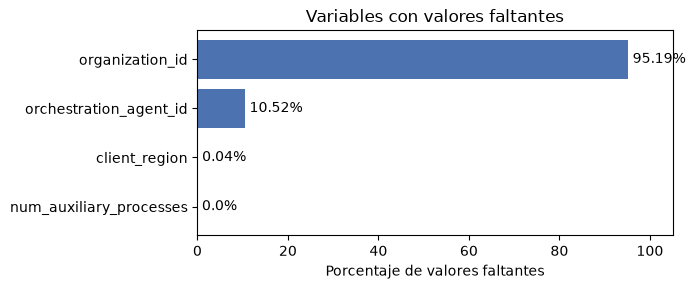

In [26]:
# VALORES FALTANTES

# Nos quedamos solo con las variables que tienen al menos un nulo
faltantes = diccionario.loc[diccionario["nulos"] > 0, ["nulos"]].copy()
faltantes["porcentaje"] = (faltantes["nulos"] / len(df) * 100).round(2)
faltantes = faltantes.sort_values("nulos", ascending=False)

print(faltantes)

# Gráfico de barras horizontales con el porcentaje de nulos
fig, ax = plt.subplots(figsize=(7, 3))
ax.barh(faltantes.index, faltantes["porcentaje"], color="#4C72B0")

# Escribimos el porcentaje al lado de cada barra
for i, v in enumerate(faltantes["porcentaje"]):
    ax.text(v + 1, i, f"{v}%", va="center")

ax.invert_yaxis()  # la variable con más nulos queda arriba
ax.set_xlim(0, 105)
ax.set_xlabel("Porcentaje de valores faltantes")
ax.set_title("Variables con valores faltantes")
plt.tight_layout()
plt.show()

Solo 4 variables tienen valores faltantes:

- **`organization_id`** (95,19%): la gran mayoría de las reservas no tiene organización asociada. El nulo probablemente significa "sin organización" y no un error de carga, así que en lugar de eliminar filas se tratará como una categoría propia.
- **`orchestration_agent_id`** (10,52%): ocurre lo mismo, el nulo probablemente significa "sin agente".
- **`client_region`** (20 filas) y **`num_auxiliary_processes`** (1 fila): son casos aislados. Se imputarán dentro del pipeline (con la moda o la mediana), ajustando la imputación solo con los datos de entrenamiento.

### 2.3 Variable objetivo

              cantidad  porcentaje
canceled_job                      
0                27887       58.29
1                19955       41.71


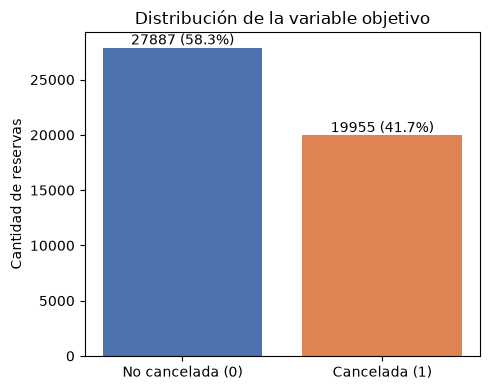

In [27]:
# DISTRIBUCIÓN DE LA VARIABLE OBJETIVO

conteo = df["canceled_job"].value_counts().sort_index()
porcentaje = df["canceled_job"].value_counts(normalize=True).sort_index() * 100

print(pd.DataFrame({"cantidad": conteo, "porcentaje": porcentaje.round(2)}))

fig, ax = plt.subplots(figsize=(5, 4))
ax.bar(["No cancelada (0)", "Cancelada (1)"], conteo.values, color=["#4C72B0", "#DD8452"])

# Escribimos el valor arriba de cada barra
for i, v in enumerate(conteo.values):
    ax.text(i, v, f"{v} ({porcentaje.values[i]:.1f}%)", ha="center", va="bottom")

ax.set_title("Distribución de la variable objetivo")
ax.set_ylabel("Cantidad de reservas")
plt.tight_layout()
plt.show()

El 58,3% de las reservas no se canceló y el 41,7% sí. Hay un desbalance moderado.

Igualmente, este desbalance justifica dos decisiones:

- Usar **`stratify`** al separar train y test, para que ambos conjuntos mantengan la misma proporción de cancelaciones.
- Evaluar con **Balanced Accuracy**. Promedia el recall de cada clase, así que un modelo que favorezca a la clase mayoritaria no obtiene un buen puntaje.

### 2.4 Categorías poco frecuentes

Las categorías con muy pocas observaciones son un problema para los modelos: no hay suficientes ejemplos para aprender su comportamiento. Identificamos las categorías que representan menos del 1% de las reservas.

In [28]:
# CATEGORÍAS POCO FRECUENTES (< 1% DE LAS RESERVAS)

umbral = 1  # porcentaje

cols_categoricas = [
    "service_tier",
    "client_type",
    "request_channel",
    "reserved_gpu_type",
    "assigned_gpu_type",
    "reservation_commitment",
    "workload_profile",
    "client_region",
]

filas = []

for col in cols_categoricas:

    # Porcentaje de reservas en cada categoría
    porc = df[col].value_counts(normalize=True) * 100

    # Categorías que no llegan al umbral
    raras = porc[porc < umbral]

    filas.append({
        "variable": col,
        "n_categorias": df[col].nunique(),
        "categorias_raras": len(raras),
        "reservas_en_categorias_raras": int(df[col].isin(raras.index).sum()),
        "ejemplos": ", ".join(raras.index[:5].astype(str)),
    })

pd.DataFrame(filas).set_index("variable")

,n_categorias,categorias_raras,reservas_en_categorias_raras,ejemplos
variable,,,,
service_tier,4,1,9,enterprise
client_type,8,3,464,"sponsored_project, high_priority_partner, unknown"
request_channel,5,2,110,"scheduler_gateway, unknown"
reserved_gpu_type,8,3,296,"GPU_T7, GPU_T3, GPU_T12"
assigned_gpu_type,9,4,670,"GPU_T7, GPU_T10, GPU_T3, GPU_T12"
reservation_commitment,3,1,12,flexible_commitment
workload_profile,4,1,177,team_project
client_region,149,135,5327,"ISR, SWE, POL, CN, NOR"


Todas las variables categóricas tienen al menos una categoría poco frecuente:

- **`client_region`** es el caso más extremo: 135 de sus 149 países representan menos del 1% de las reservas cada uno.
- En **`client_type`** y **`request_channel`** aparece la categoría `unknown` con una sola reserva.
- En **`service_tier`**, `enterprise` tiene solo 9 reservas. 
- En **`reservation_commitment`**, `flexible_commitment` tiene solo 12.

Para evitar que el modelo aprenda patrones a partir de muy pocos casos, estas categorías se agruparán en una categoría **"otros"**. La agrupación se definirá usando solo el conjunto de entrenamiento.

### 2.5 Conclusiones de la exploración inicial

| Hallazgo | Decisión |
|---|---|
| `execution_status` y `execution_status_date` contienen el resultado de la reserva | Eliminarlas (data leakage) |
| `total_gpu_hours` y `total_processes` son sumas de otras variables | Eliminarlas (redundantes) |
| `organization_id` y `orchestration_agent_id` son identificadores con muchos nulos | Tratarlas como categóricas, con el nulo como categoría "sin organización" / "sin agente" |
| `client_region` y `num_auxiliary_processes` tienen pocos nulos | Imputar dentro del pipeline |
| Desbalance moderado (58% / 42%) | Usar `stratify` y Balanced Accuracy |
| Categorías poco frecuentes | Agruparlas en "otros" |

## 3. Separación en train y test

Antes de analizar la relación de las variables con el target, separamos un conjunto de **test** que no se usará hasta la evaluación final. Antes del split hay dos pasos: eliminar las variables con leakage y decidir qué hacer con las filas duplicadas.

### 3.1 Eliminación de variables con leakage

Como se vio en la sección 1, `execution_status` y `execution_status_date` contienen el resultado de la reserva. Se eliminan antes del split para que no lleguen a ningún modelo.

In [29]:
# ELIMINACIÓN DE VARIABLES CON LEAKAGE

cols_leakage = ["execution_status", "execution_status_date"]

# Trabajamos sobre una copia para no modificar el df original
df_modelo = df.drop(columns=cols_leakage)

print("Columnas antes:", df.shape[1])
print("Columnas después:", df_modelo.shape[1])

Columnas antes: 34
Columnas después: 32


### 3.2 Filas duplicadas

Verificamos si hay reservas con exactamente los mismos valores en todas las variables (sin contar el target).

In [30]:
# FILAS DUPLICADAS

# Columnas que describen la reserva (todas menos el target)
cols_features = df_modelo.columns.drop("canceled_job")

# keep=False marca todas las copias, no solo las repetidas
duplicadas = df_modelo.duplicated(subset=cols_features, keep=False)
print(f"Filas con al menos una copia idéntica: {duplicadas.sum()} ({duplicadas.mean() * 100:.1f}%)")

# Asignamos un número de grupo a cada combinación distinta de valores.
# Las filas idénticas comparten el mismo número de grupo.
# dropna=False hace que los nulos también se consideren iguales entre sí.
grupos = df_modelo.groupby(list(cols_features), dropna=False).ngroup()

tamanio_grupos = grupos.value_counts()
print("Grupos con más de una fila:", (tamanio_grupos > 1).sum())
print("Tamaño del grupo más grande:", tamanio_grupos.max())

print("\nCantidad de grupos según su tamaño (primeros 10):")
print(tamanio_grupos[tamanio_grupos > 1].value_counts().sort_index().head(10))

Filas con al menos una copia idéntica: 19435 (40.6%)
Grupos con más de una fila: 3499
Tamaño del grupo más grande: 180

Cantidad de grupos según su tamaño (primeros 10):
count
2     2100
3      410
4      204
5      128
6       72
7       49
8       44
9       41
10      61
11      28
Name: count, dtype: int64


El 40,6% de las filas (19.435) tiene al menos una copia idéntica. Forman 3.499 grupos: la mayoría son pares, pero hay grupos de hasta 180 filas iguales.

El dataset no tiene un identificador de reserva, así que no se puede saber con certeza si son errores de carga o reservas distintas. Grupos tan grandes (misma fecha, mismo agente, mismo precio) sugieren reservas en bloque: un cliente que reserva muchas GPUs a la vez. Por eso no se eliminan.

El riesgo de conservarlas es que una copia quede en train y otra en test: el modelo se evaluaría sobre filas que ya vio y la métrica saldría optimista. Para evitarlo, el split se hace por grupos.

### 3.3 Split estratificado por grupos

Usamos `StratifiedGroupKFold` con 5 folds y tomamos uno como test (20%). Así se cumplen dos condiciones:

- **Estratificado:** train y test mantienen la proporción de cancelaciones.
- **Por grupos:** cada grupo de filas idénticas queda entero en train o en test.

La asignación de los grupos es aleatoria. La semilla (`random_state=42`) se fija una sola vez y no se cambia según los resultados, para no elegir un test "a medida". Los mismos grupos se usarán después en la validación cruzada.

In [31]:
# SPLIT TRAIN / TEST

from sklearn.model_selection import StratifiedGroupKFold

X = df_modelo.drop(columns="canceled_job")
y = df_modelo["canceled_job"]

sgkf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)

# Tomamos el primer fold como test (1 de 5 = 20%)
idx_train, idx_test = next(sgkf.split(X, y, groups=grupos))

X_train, X_test = X.iloc[idx_train], X.iloc[idx_test]
y_train, y_test = y.iloc[idx_train], y.iloc[idx_test]

# Guardamos los grupos de train para usarlos en la validación cruzada
grupos_train = grupos.iloc[idx_train]

# Verificación 1: tamaño y proporción de cancelaciones en cada conjunto
print(pd.DataFrame({
    "filas": [len(y_train), len(y_test)],
    "porc_filas": [round(len(y_train) / len(y) * 100, 2), round(len(y_test) / len(y) * 100, 2)],
    "porc_canceladas": [round(y_train.mean() * 100, 2), round(y_test.mean() * 100, 2)],
}, index=["train", "test"]))

# Verificación 2: ningún grupo de duplicados aparece en ambos conjuntos
compartidos = set(grupos.iloc[idx_train]) & set(grupos.iloc[idx_test])
print("\nGrupos presentes en train y en test a la vez:", len(compartidos))

       filas  porc_filas  porc_canceladas
train  38274        80.0            41.71
test    9568        20.0            41.70

Grupos presentes en train y en test a la vez: 0


El split quedó con 38.274 filas en train (80%) y 9.568 en test (20%), ambos con 41,7% de cancelaciones y ningún grupo de duplicados aparece en los dos conjuntos.

A partir de acá, el test no se vuelve a mirar hasta la evaluación final. Todo el análisis y las decisiones siguientes se hacen solo con train.

## 4. Análisis exploratorio

Con el test ya separado, se analiza la relación entre cada variable y la cancelación. Todo este análisis usa **únicamente el conjunto de entrenamiento**: mirar el test en esta etapa equivaldría a tomar decisiones a partir de datos que deben quedar reservados para la evaluación final.

### 4.1 Variables numéricas

El análisis de las variables numéricas tiene dos partes:

1. Correlación entre variables: busca variables que repiten la misma información (redundancia).
2. Relación con el target: busca qué variables ayudan a predecir la cancelación.

En ambas se usan dos coeficientes de correlación:

- Pearson mide relaciones lineales y es sensible a los valores extremos.
- Spearman trabaja con el orden de los valores (rangos), así que detecta cualquier relación monótona y es robusto a outliers y a distribuciones asimétricas, como las de `hours_before_execution` o `queue_wait_time`.

Los identificadores (`orchestration_agent_id` y `organization_id`) quedan fuera de este análisis. Como se explicó en la sección 1, son etiquetas y no números: el agente 200 no es "mayor" que el agente 100, así que calcular su correlación no tiene sentido. En el preprocesamiento se tratan como categóricas.

#### Correlación entre variables

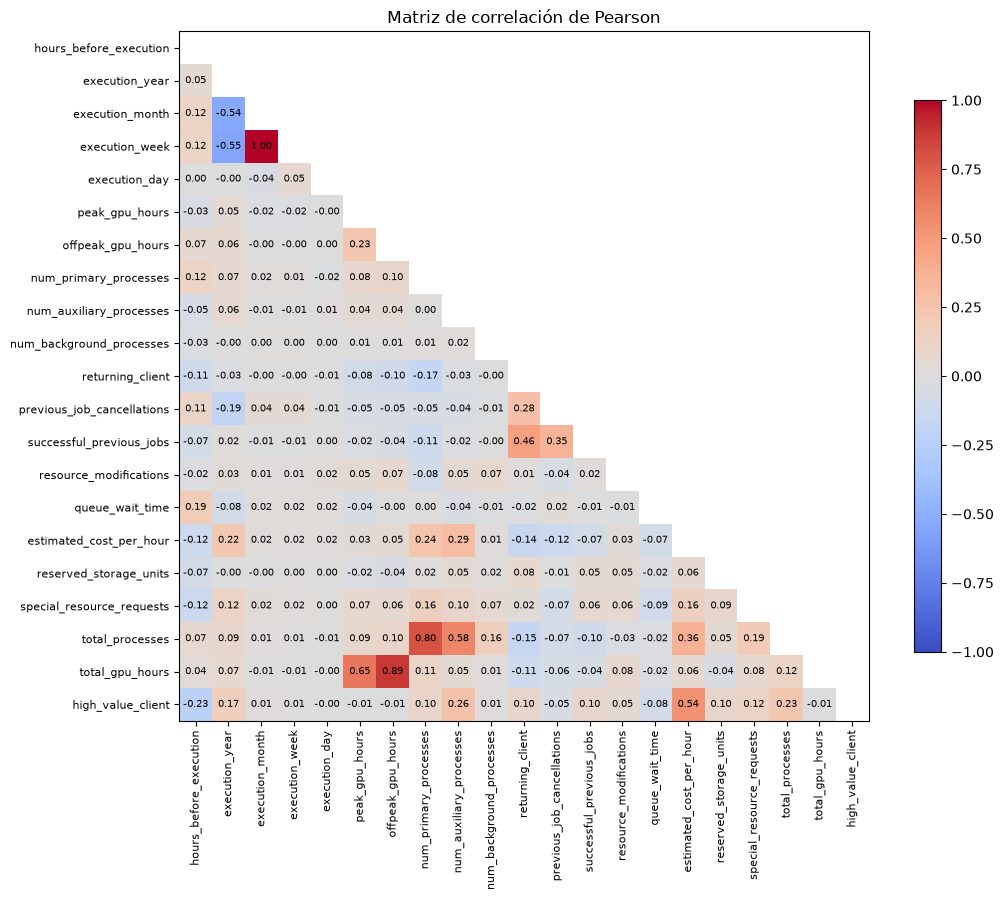

pearson  spearman
variable_1                 variable_2                                 
execution_month            execution_week               1.00      1.00
num_primary_processes      total_processes              0.80      0.90
offpeak_gpu_hours          total_gpu_hours              0.89      0.80
returning_client           successful_previous_jobs     0.46      0.79
estimated_cost_per_hour    high_value_client            0.54      0.58
peak_gpu_hours             total_gpu_hours              0.65      0.56
execution_year             execution_week              -0.55     -0.55
                           execution_month             -0.54     -0.54
num_auxiliary_processes    total_processes              0.58      0.46
estimated_cost_per_hour    total_processes              0.36      0.33
previous_job_cancellations successful_previous_jobs     0.35      0.13

Máximo de semanas distintas para una misma fecha: 1


In [32]:
# CORRELACIÓN ENTRE VARIABLES NUMÉRICAS

# Juntamos features y target en un solo DataFrame, solo para el análisis
train = X_train.copy()
train["canceled_job"] = y_train

# Los identificadores son etiquetas, no números: quedan fuera del análisis de correlación
cols_identificadores = ["orchestration_agent_id", "organization_id"]

# Numéricas: todas las que no son categóricas de texto ni identificadores
cols_numericas_eda = [c for c in X_train.columns
                      if c not in cols_categoricas and c not in cols_identificadores]

corr_pearson = train[cols_numericas_eda].corr(method="pearson")
corr_spearman = train[cols_numericas_eda].corr(method="spearman")

# 1) MATRIZ DE CORRELACIÓN DE PEARSON
# Mostramos solo el triángulo inferior, porque la matriz es simétrica
mascara = np.triu(np.ones(corr_pearson.shape, dtype=bool))
valores = corr_pearson.mask(mascara)

fig, ax = plt.subplots(figsize=(11, 9))
im = ax.imshow(valores, cmap="coolwarm", vmin=-1, vmax=1)

# Escribimos el valor en cada celda
for i in range(len(corr_pearson)):
    for j in range(i):
        ax.text(j, i, f"{corr_pearson.iloc[i, j]:.2f}", ha="center", va="center", fontsize=7)

ax.set_xticks(range(len(corr_pearson)))
ax.set_xticklabels(corr_pearson.columns, rotation=90, fontsize=8)
ax.set_yticks(range(len(corr_pearson)))
ax.set_yticklabels(corr_pearson.columns, fontsize=8)
ax.set_title("Matriz de correlación de Pearson")
fig.colorbar(im, ax=ax, shrink=0.8)
plt.tight_layout()
plt.show()

# 2) PARES MÁS CORRELACIONADOS: PEARSON vs SPEARMAN
# Nos quedamos con los pares con |r| >= 0,3 en alguno de los dos coeficientes
triangulo = np.triu(np.ones(corr_pearson.shape, dtype=bool), k=1)
pares = pd.DataFrame({
    "pearson": corr_pearson.where(triangulo).stack(),
    "spearman": corr_spearman.where(triangulo).stack(),
})
pares = pares[(pares["pearson"].abs() >= 0.3) | (pares["spearman"].abs() >= 0.3)]
pares = pares.reindex(pares["spearman"].abs().sort_values(ascending=False).index)
pares.index.names = ["variable_1", "variable_2"]

display(pares.round(2))

# 3) ¿execution_week queda determinada por la fecha (año, mes y día)?
semanas_por_fecha = train.groupby(["execution_year", "execution_month", "execution_day"])["execution_week"].nunique()
print("Máximo de semanas distintas para una misma fecha:", semanas_por_fecha.max())

Los pares con correlación alta o moderada son:

- `execution_month` y `execution_week` (1,00 en ambos coeficientes): son prácticamente la misma variable. Además, la semana queda completamente determinada por la fecha: cada combinación de año, mes y día tiene una única semana.
- `total_gpu_hours` y `total_processes` con sus componentes (entre 0,46 y 0,90): confirma lo verificado en la sección 1, son sumas de otras columnas.
- `execution_year` con `execution_month` y `execution_week` (-0,55): no es una relación real, sino un efecto del período que cubre el dataset. 2015 solo tiene reservas de julio a diciembre y 2017 de enero a agosto, por lo que el año "predice" en parte el mes.
- `returning_client` y `successful_previous_jobs` (0,46 Pearson, 0,79 Spearman): quien vuelve a la plataforma tiene reservas previas. Spearman es mucho más alto porque la relación es monótona pero no lineal (casi todos los valores de `successful_previous_jobs` son 0). Aportan información distinta: una indica si el cliente volvió y la otra cuántas reservas completó.
- `estimated_cost_per_hour` y `high_value_client` (0,54 y 0,58): coincide con lo visto en la sección 1. La relación es moderada y no hay un umbral que las separe, así que no son redundantes.

#### Relación con el target

Para cada variable se compara su promedio en cada clase y se calculan tres medidas: Pearson, Spearman e información mutua. La información mutua mide cuánto se reduce la incertidumbre sobre el target al conocer la variable. A diferencia de las correlaciones, detecta cualquier tipo de relación, incluso las que no son monótonas, y vale 0 cuando la variable y el target son independientes.

In [33]:
# RELACIÓN DE LAS VARIABLES NUMÉRICAS CON EL TARGET

from sklearn.feature_selection import mutual_info_classif

# Valor promedio de cada variable en cada clase
comparacion = train.groupby("canceled_job")[cols_numericas_eda].mean().T
comparacion.columns = ["no_cancelada", "cancelada"]
comparacion["diferencia"] = comparacion["cancelada"] - comparacion["no_cancelada"]

# Correlación de cada variable con el target
comparacion["pearson"] = [train[c].corr(train["canceled_job"], method="pearson")
                          for c in cols_numericas_eda]
comparacion["spearman"] = [train[c].corr(train["canceled_job"], method="spearman")
                           for c in cols_numericas_eda]

# Información mutua: no admite nulos, así que completamos el único faltante con la mediana
X_mi = train[cols_numericas_eda].fillna(train[cols_numericas_eda].median())
comparacion["info_mutua"] = mutual_info_classif(X_mi, train["canceled_job"], random_state=42)

# Ordenamos por información mutua: arriba las más informativas
comparacion.sort_values("info_mutua", ascending=False).round(3)

,no_cancelada,cancelada,diferencia,pearson,spearman,info_mutua
hours_before_execution,81.148,143.399,62.251,0.282,0.305,0.106
estimated_cost_per_hour,5.282,5.217,-0.065,-0.013,-0.038,0.096
special_resource_requests,0.738,0.279,-0.459,-0.290,-0.323,0.057
previous_job_cancellations,0.020,0.165,0.145,0.169,0.279,0.050
queue_wait_time,2.210,4.776,2.566,0.058,0.120,0.028
resource_modifications,0.262,0.083,-0.179,-0.148,-0.190,0.019
reserved_storage_units,0.041,0.000,-0.041,-0.132,-0.132,0.016
total_gpu_hours,23.294,24.499,1.205,0.039,0.028,0.014
total_processes,1.928,1.946,0.018,0.014,0.019,0.008
successful_previous_jobs,0.221,0.018,-0.203,-0.057,-0.098,0.007


Las variables numéricas más relacionadas con la cancelación son:

- `hours_before_execution` (Spearman 0,31; información mutua 0,106, la más alta): las canceladas se reservaron con 143 horas de anticipación en promedio, frente a 81 las no canceladas. Reservar con mucha antelación da más tiempo y más motivos para cancelar.
- `special_resource_requests` (Spearman -0,32): las reservas que no se cancelan piden en promedio 0,74 solicitudes especiales, contra 0,28 las que sí se cancelan. Pedir extras parece indicar un cliente comprometido con la reserva.
- `previous_job_cancellations` (Spearman 0,28, frente a 0,17 de Pearson): quien ya canceló antes vuelve a cancelar. La diferencia entre coeficientes se debe a que casi todos los valores son 0 y unos pocos son muy altos.
- `resource_modifications` (-0,19) y `reserved_storage_units` (-0,13): modificar la reserva o reservar almacenamiento indican compromiso. En train, ninguna reserva cancelada tiene almacenamiento reservado.

El caso de `estimated_cost_per_hour` muestra por qué no alcanza con mirar la correlación: su Pearson es prácticamente 0 (-0,01) y el promedio casi no cambia entre clases, pero es la segunda variable con mayor información mutua (0,096). La relación con la cancelación existe, pero no es lineal ni monótona.

En el otro extremo, las variables temporales (`execution_year`, `execution_month`, `execution_week`, `execution_day`) y las de procesos tienen correlaciones e información mutua prácticamente nulas. Esto no alcanza para descartarlas: estas medidas analizan cada variable por separado, y un modelo de árboles puede aprovecharlas combinadas con otras.

#### Variables a eliminar

A partir de los dos análisis anteriores, se eliminan las siguientes variables:

| Variable | Motivo |
|---|---|
| `total_gpu_hours` | Es la suma exacta de `peak_gpu_hours` y `offpeak_gpu_hours` (sección 1). No agrega información y genera colinealidad en modelos lineales. |
| `total_processes` | Es la suma exacta de los tres tipos de procesos (sección 1). Mismo motivo. |
| `execution_week` | Tiene correlación 1,00 con `execution_month` y queda determinada por año, mes y día, así que no aporta nada que no esté en esas tres variables. Se elimina la semana y no el mes porque el mes no queda determinado por la semana: hay semanas que caen en dos meses distintos. |

El resto de las variables se conserva. Los casos que podrían generar dudas son tres:

- **`estimated_cost_per_hour`**: su correlación con el target es casi nula (Pearson −0,01), pero es la segunda variable con mayor información mutua (0,096). Las dos medidas no se contradicen. La correlación solo detecta relaciones en las que, al aumentar el costo, la cancelación aumenta o disminuye siempre en el mismo sentido. La información mutua detecta cualquier tipo de relación, por ejemplo que ciertos rangos de precio cancelen mucho y otros poco. Eliminarla por su correlación sería descartar una variable que sí aporta información.
- **Variables con poca relación individual con el target** (`execution_day`, las de procesos, `returning_client`, etc.): todas las medidas usadas analizan cada variable por separado. Una variable puede no servir sola y ser útil combinada con otras. Por ejemplo, el día del mes junto con el mes identifica fechas puntuales, como feriados. Los modelos de árboles detectan este tipo de combinaciones, así que la decisión de eliminarlas se toma más adelante con el modelo, comparando el rendimiento con y sin ellas.
- **`execution_year`**: el train incluye los tres años del dataset (2015, 2016 y 2017), así que el modelo los conoce todos. El riesgo aparecería si los datos de evaluación correspondieran a un año nuevo: el modelo no tendría ejemplos de ese año y podría aprender patrones que no se repiten. Como el dataset cubre un período continuo sin huecos, es más probable que el conjunto de evaluación pertenezca al mismo período. Igual, su impacto se medirá más adelante entrenando con y sin ella.

In [34]:
# ELIMINACIÓN DE VARIABLES REDUNDANTES

cols_eliminar = ["total_gpu_hours", "total_processes", "execution_week"]

# Se eliminan de train y de test. Quitar columnas no usa información de los datos,
# así que hacerlo en ambos conjuntos no genera leakage.
# errors="ignore" permite volver a correr la celda sin que falle.
X_train = X_train.drop(columns=cols_eliminar, errors="ignore")
X_test = X_test.drop(columns=cols_eliminar, errors="ignore")
train = train.drop(columns=cols_eliminar, errors="ignore")

print("Columnas de X_train:", X_train.shape[1])
print("Columnas de X_test:", X_test.shape[1])

Columnas de X_train: 28
Columnas de X_test: 28


### 4.2 Variables categóricas

El análisis de las variables categóricas sigue la misma lógica que el de las numéricas, pero con otras herramientas, porque Pearson y Spearman solo se pueden calcular sobre números. Tiene tres partes:

1. Tasa de cancelación por categoría, para las variables categóricas y para los identificadores.
2. Asociación entre variables categóricas: busca variables que repiten la misma información.
3. Asociación con el target: mide qué variables categóricas se relacionan más con la cancelación.

#### Tasa de cancelación por categoría

Para cada categoría se calcula la proporción de reservas canceladas. Si las tasas son muy distintas entre categorías, la variable ayuda a predecir la cancelación. Si todas quedan cerca del promedio del train (41,7%), aporta poco.

Este análisis complementa al test de chi-cuadrado de más abajo: la V de Cramér resume en un solo número cuánto difieren las tasas y sirve para comparar variables entre sí, pero no indica qué categorías cancelan más. Eso es lo que muestra esta tabla.

Se muestran solo las categorías con al menos 30 reservas, porque con menos casos la proporción puede salir alta o baja por azar.

In [35]:
# TASA DE CANCELACIÓN POR CATEGORÍA

# Con menos de 30 reservas la proporción no es confiable
minimo_reservas = 30

for col in cols_categoricas:

    tabla = train.groupby(col).agg(
        reservas=("canceled_job", "size"),
        tasa_cancelacion=("canceled_job", "mean"),
    )

    # Dejamos afuera las categorías con muy pocos casos
    tabla = tabla[tabla["reservas"] >= minimo_reservas]

    # client_region tiene 149 categorías: mostramos solo las más frecuentes
    if col == "client_region":
        tabla = tabla.sort_values("reservas", ascending=False).head(8)
    else:
        tabla = tabla.sort_values("tasa_cancelacion", ascending=False)

    print(f"\n=== {col} ===")
    print(tabla.round(3))


=== service_tier ===
              reservas  tasa_cancelacion
service_tier                            
standard         30049             0.429
basic             5049             0.377
priority          3168             0.369

=== client_type ===
                       reservas  tasa_cancelacion
client_type                                      
research_consortium        6638             0.668
managed_account            8361             0.440
cloud_marketplace         18521             0.376
enterprise_client          1460             0.234
high_priority_partner       129             0.209
independent_client         2910             0.167
sponsored_project           254             0.118

=== request_channel ===
                   reservas  tasa_cancelacion
request_channel                              
broker_platform       33269             0.451
enterprise_portal      1659             0.220
api_direct             3260             0.180
scheduler_gateway        85             0.094



Hay variables categóricas que separan muy bien las dos clases:

- **`reservation_commitment`**: las reservas con `locked_allocation` se cancelan en el 99,8% de los casos (6.274 reservas), frente al 30,3% de `no_commitment`. Es la variable más predictiva del dataset. Es información contractual conocida al momento de reservar, así que no constituye leakage, pero una variable que determina el resultado casi por completo merece mencionarse explícitamente.
- **`client_type`**: va del 66,8% en `research_consortium` al 11,8% en `sponsored_project`.
- **`client_region`**: Portugal (PRT) concentra el 39,2% del train y cancela el 64,9%, mientras que los demás países frecuentes cancelan entre el 17,5% (DEU) y el 38,3% (ITA).
- **`request_channel`**: `broker_platform` cancela el 45,1% y `api_direct` el 18,0%. Reservar a través de un intermediario se asocia a mucha más cancelación que hacerlo directo por API.
- **`workload_profile`**: `single_experiment` cancela el 46,1% y `multi_run_experiment` el 26,6%.

#### Identificadores

Los identificadores quedaron fuera del análisis de correlación porque son etiquetas. Acá se analizan igual que las categóricas: tasa de cancelación por valor, mostrando los nulos como "sin agente" y "sin organización". Se consideran solo los valores con al menos 100 reservas.

In [36]:
# TASA DE CANCELACIÓN POR IDENTIFICADOR

minimo_reservas_id = 100

identificadores = {
    "orchestration_agent_id": "sin agente",
    "organization_id": "sin organización",
}

for col, etiqueta_nulo in identificadores.items():

    # Pasamos el id a texto y reemplazamos el nulo por su etiqueta
    ids = train[col].fillna(-1).astype(int).astype(str).replace("-1", etiqueta_nulo)

    tabla = train.groupby(ids)["canceled_job"].agg(
        reservas="size",
        tasa_cancelacion="mean",
    )
    tabla = tabla[tabla["reservas"] >= minimo_reservas_id]

    print(f"\n=== {col} ({len(tabla)} valores con al menos {minimo_reservas_id} reservas) ===")
    print(tabla.sort_values("reservas", ascending=False).head(8).round(3))
    print(f"Rango de la tasa de cancelación: {tabla['tasa_cancelacion'].min():.1%} "
          f"a {tabla['tasa_cancelacion'].max():.1%}")


=== orchestration_agent_id (35 valores con al menos 100 reservas) ===
                        reservas  tasa_cancelacion
orchestration_agent_id                            
9                          15265             0.419
sin agente                  4030             0.320
1                           3153             0.712
14                          1722             0.172
7                           1705             0.130
6                           1316             0.372
37                           824             0.623
28                           805             0.065
Rango de la tasa de cancelación: 6.5% a 100.0%

=== organization_id (5 valores con al menos 100 reservas) ===
                  reservas  tasa_cancelacion
organization_id                             
sin organización     36415             0.427
40                     446             0.078
67                     146             0.712
45                     117             0.111
153                    115             

Aunque no se pueden analizar con Pearson ni Spearman, los identificadores están entre las variables más informativas del dataset:

- **`orchestration_agent_id`**: entre los 35 agentes con al menos 100 reservas, la tasa de cancelación va del 6,5% al 100%. El agente 1 cancela el 71,2% y el agente 28 el 6,5%. El agente 9 concentra el 39,9% del train.
- **`organization_id`**: el 95% de las reservas no tiene organización y cancela el 42,7%, prácticamente igual que el promedio. Entre las pocas organizaciones frecuentes también hay diferencias grandes: la 40 cancela el 7,8% y la 67 el 71,2%.

Esto confirma la decisión de la sección 2.5 de tratarlos como categóricas.

#### Asociación entre variables categóricas

Para medir la relación entre dos variables categóricas se usa el test de chi-cuadrado de independencia. Compara la tabla de frecuencias observada (cuántas reservas hay en cada combinación de categorías) con la que se esperaría si las variables fueran independientes. Cuanto más se alejan, mayor es el estadístico chi-cuadrado.

El chi-cuadrado crece con la cantidad de filas y de categorías, así que no sirve para comparar variables entre sí. Para eso se usa la V de Cramér, que lo lleva a una escala de 0 (independientes) a 1 (una variable determina a la otra) y se lee como una correlación. Se aplica la corrección de Bergsma, porque sin ella la V sale inflada en variables con muchas categorías, como `client_region` o los identificadores.

A diferencia de Pearson y Spearman, la V de Cramér sí se puede calcular para los identificadores, porque los trata como etiquetas. Por eso acá se incluyen junto con las demás categóricas. Los nulos se cuentan como una categoría más ("sin dato"), igual que en el preprocesamiento.

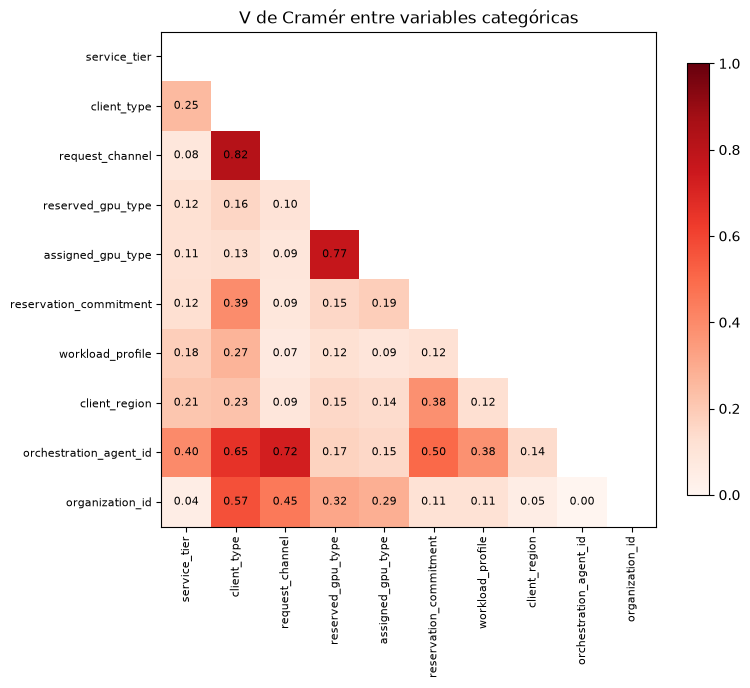

v_cramer
variable_1             variable_2                      
client_type            request_channel             0.82
reserved_gpu_type      assigned_gpu_type           0.77
request_channel        orchestration_agent_id      0.72
client_type            orchestration_agent_id      0.65
                       organization_id             0.57
reservation_commitment orchestration_agent_id      0.50
request_channel        organization_id             0.45
service_tier           orchestration_agent_id      0.40
client_type            reservation_commitment      0.39
reservation_commitment client_region               0.38
workload_profile       orchestration_agent_id      0.38
reserved_gpu_type      organization_id             0.32

Conociendo client_type se acierta request_channel en el 98.3% de las reservas
Conociendo request_channel se acierta client_type en el 59.2% de las reservas
Conociendo reserved_gpu_type se acierta assigned_gpu_type en el 90.9% de las reservas


In [37]:
# ASOCIACIÓN ENTRE VARIABLES CATEGÓRICAS (V DE CRAMÉR)

from scipy.stats import chi2_contingency


def v_cramer(a, b):
    """
    V de Cramér entre dos variables categóricas, con la corrección de Bergsma.
    Va de 0 (independientes) a 1 (una determina a la otra).
    La corrección reduce el sesgo hacia arriba en variables con muchas categorías.
    """
    tabla = pd.crosstab(a, b)
    chi2 = chi2_contingency(tabla, correction=False)[0]
    n = tabla.values.sum()
    r, k = tabla.shape

    phi2 = chi2 / n
    phi2_corr = max(0, phi2 - (k - 1) * (r - 1) / (n - 1))
    r_corr = r - (r - 1) ** 2 / (n - 1)
    k_corr = k - (k - 1) ** 2 / (n - 1)

    return np.sqrt(phi2_corr / min(k_corr - 1, r_corr - 1))


# Categóricas de texto + identificadores
cols_cat_eda = list(cols_categoricas) + cols_identificadores

# Los nulos se tratan como una categoría más, igual que en el preprocesamiento
train_cat = train[cols_cat_eda].astype("string").fillna("sin dato")

# 1) MATRIZ DE V DE CRAMÉR
matriz_v = pd.DataFrame(
    [[v_cramer(train_cat[a], train_cat[b]) for b in cols_cat_eda] for a in cols_cat_eda],
    index=cols_cat_eda, columns=cols_cat_eda,
)

# Mostramos solo el triángulo inferior, porque la matriz es simétrica
mascara = np.triu(np.ones(matriz_v.shape, dtype=bool))
valores = matriz_v.mask(mascara)

fig, ax = plt.subplots(figsize=(8, 7))
im = ax.imshow(valores, cmap="Reds", vmin=0, vmax=1)

# Escribimos el valor en cada celda
for i in range(len(matriz_v)):
    for j in range(i):
        ax.text(j, i, f"{matriz_v.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8)

ax.set_xticks(range(len(matriz_v)))
ax.set_xticklabels(matriz_v.columns, rotation=90, fontsize=8)
ax.set_yticks(range(len(matriz_v)))
ax.set_yticklabels(matriz_v.columns, fontsize=8)
ax.set_title("V de Cramér entre variables categóricas")
fig.colorbar(im, ax=ax, shrink=0.8)
plt.tight_layout()
plt.show()

# 2) PARES MÁS ASOCIADOS (V >= 0,3)
triangulo = np.triu(np.ones(matriz_v.shape, dtype=bool), k=1)
pares_cat = matriz_v.where(triangulo).stack().rename("v_cramer").to_frame()
pares_cat = pares_cat[pares_cat["v_cramer"] >= 0.3].sort_values("v_cramer", ascending=False)
pares_cat.index.names = ["variable_1", "variable_2"]

display(pares_cat.round(2))


# 3) ¿UNA VARIABLE DETERMINA A LA OTRA?
# Porcentaje de reservas en las que, conociendo la primera variable,
# se acierta la segunda eligiendo su categoría más frecuente
def porcentaje_determinado(a, b):
    mas_frecuente = train_cat.groupby(a)[b].transform(lambda s: s.mode().iloc[0])
    return (mas_frecuente == train_cat[b]).mean() * 100


for a, b in [("client_type", "request_channel"), ("request_channel", "client_type"),
             ("reserved_gpu_type", "assigned_gpu_type")]:
    print(f"Conociendo {a} se acierta {b} en el {porcentaje_determinado(a, b):.1f}% de las reservas")

Los pares más asociados son:

- `client_type` y `request_channel` (0,82): cada tipo de cliente reserva casi siempre por el mismo canal. Conociendo el tipo de cliente se acierta el canal en el 98,3% de las reservas, pero al revés solo en el 59,2%. Dentro de `broker_platform` conviven `cloud_marketplace`, `managed_account` y `research_consortium`, que cancelan de forma muy distinta (37,6%, 44,0% y 66,8%). Es decir, `client_type` contiene casi toda la información de `request_channel` y además agrega la suya.
- `reserved_gpu_type` y `assigned_gpu_type` (0,77): en el 90,9% de las reservas la GPU asignada es la más común para el tipo reservado. En qué casos difieren se analiza en la sección 4.5.
- `orchestration_agent_id` con `request_channel` (0,72), `client_type` (0,65) y `reservation_commitment` (0,50): cada agente trabaja con ciertos tipos de cliente, canales y contratos. Esto explica en parte por qué el agente es tan informativo: resume información de varias variables.
- `organization_id` con `client_type` (0,57) y `request_channel` (0,45): las reservas con organización corresponden a ciertos tipos de cliente.

El resto de los pares tiene asociaciones moderadas o bajas (V menor a 0,4).

#### Asociación con el target

Se aplica el mismo test entre cada variable categórica y `canceled_job`. Además del estadístico y su p-valor se muestra la V de Cramér, que es la medida que permite comparar las variables entre sí.

In [38]:
# ASOCIACIÓN DE LAS VARIABLES CATEGÓRICAS CON EL TARGET

filas_chi2 = []

for col in cols_cat_eda:

    tabla = pd.crosstab(train_cat[col], train["canceled_job"])
    chi2, p_valor, _, _ = chi2_contingency(tabla, correction=False)

    filas_chi2.append({
        "variable": col,
        "categorias": train_cat[col].nunique(),
        "chi2": chi2,
        "p_valor": p_valor,
        "v_cramer": v_cramer(train_cat[col], train["canceled_job"]),
    })

asociacion_target = pd.DataFrame(filas_chi2).set_index("variable")

# Ordenamos por V de Cramér: arriba las más asociadas con la cancelación
asociacion_target.sort_values("v_cramer", ascending=False).round(3)

,categorias,chi2,p_valor,v_cramer
variable,,,,
reservation_commitment,3,10414.196,0.0,0.522
client_region,142,6509.495,0.0,0.408
orchestration_agent_id,188,6468.240,0.0,0.405
client_type,8,2930.554,0.0,0.276
assigned_gpu_type,9,1252.352,0.0,0.180
request_channel,5,1211.233,0.0,0.178
workload_profile,4,1092.372,0.0,0.169
organization_id,159,933.695,0.0,0.142
reserved_gpu_type,8,203.285,0.0,0.072


- Todas las variables tienen un p-valor prácticamente 0, así que en todas se rechaza la independencia con el target. Con 38.274 reservas el test detecta incluso relaciones muy débiles, por eso el p-valor no sirve para ordenarlas y se usa la V de Cramér.
- `reservation_commitment` es la más asociada (0,52), por el 99,8% de cancelación de `locked_allocation`.
- `client_region` (0,41) y `orchestration_agent_id` (0,41) le siguen, por encima de `client_type` (0,28). Las dos tienen muchas categorías, pero la corrección de Bergsma casi no cambia su valor, así que la asociación no es un efecto de la cantidad de categorías. Esto confirma lo visto en la tabla de identificadores: el agente es una de las variables más informativas del dataset.
- `assigned_gpu_type` (0,18) está bastante más asociada que `reserved_gpu_type` (0,07). Es coherente con lo que se analiza en la sección 4.5: la información está en la GPU asignada, que se conoce después de reservar.
- `service_tier` (0,05) y `reserved_gpu_type` (0,07) son las menos asociadas con la cancelación.


#### Conclusiones análisis de variables categóricas

No se elimina ninguna variable categórica. El criterio es el mismo que en la sección 4.1: una variable se elimina solo si su información ya está completa en otras.

| Variable | Decisión | Motivo |
|---|---|---|
| `request_channel` | Se conserva | Es la única candidata: tiene V 0,82 con `client_type` y queda determinada por ella en el 98,3% de las reservas. Pero no es redundante al 100% como `execution_week`: queda un 1,7% de reservas que se apartan de la regla (por ejemplo, 203 de `sponsored_project` reservan por `api_direct`), y esos casos pueden aportar información. Su aporte se evaluará en la etapa de optimización, entrenando con y sin ella. |
| `reserved_gpu_type` y `service_tier` | Se conservan | Son las menos asociadas con el target, pero la consigna pide analizar los errores del modelo según estas cohortes. Además, `reserved_gpu_type` es la GPU que se conoce al momento de reservar. |
| `assigned_gpu_type` | Se conserva por ahora | Tiene V 0,77 con `reserved_gpu_type`, pero lo que se discute no es si es redundante sino si contiene información posterior a la reserva. Se analiza en la sección 4.5. |
| `orchestration_agent_id` y `organization_id` | Se conservan | Están asociados con varias variables, pero ninguna los determina, y el agente es una de las variables más asociadas con el target. |

### 4.3 Análisis por cohortes

Una cohorte es un subconjunto de reservas que comparten una característica: todas las del mismo tipo de cliente, las del mismo nivel de servicio, las que pidieron el mismo tipo de GPU. Mirar el dataset completo da un solo número, el 41,7% de cancelación global, y ese promedio puede esconder comportamientos muy distintos por debajo.

Analizamos tres cohortes: `client_type`, `service_tier` y `reserved_gpu_type`.

De cada una miramos dos cosas. El porcentaje de cancelación dice qué tan distinta es del promedio. La cantidad de reservas dice cuánto pesa en el resultado final. Hacen falta las dos: una cohorte que cancela el 90% pero reúne diez reservas no mueve la aguja, mientras que una que cancela el 45% y concentra la mitad del dataset determina casi todo el resultado global.

Acá el análisis sirve para ver qué variables separan de verdad antes de entrenar nada. Estas mismas cohortes se reutilizan en el análisis de errores, para ver si el modelo falla parejo o si hay subgrupos donde anda sistemáticamente peor.


=== client_type ===
                       reservas  tasa_cancelacion  porc_del_train
client_type                                                      
cloud_marketplace         18521             0.376          48.391
managed_account            8361             0.440          21.845
research_consortium        6638             0.668          17.343
independent_client         2910             0.167           7.603
enterprise_client          1460             0.234           3.815
sponsored_project           254             0.118           0.664
high_priority_partner       129             0.209           0.337
unknown                       1             1.000           0.003

=== service_tier ===
              reservas  tasa_cancelacion  porc_del_train
service_tier                                            
standard         30049             0.429          78.510
basic             5049             0.377          13.192
priority          3168             0.369           8.277
enterprise  

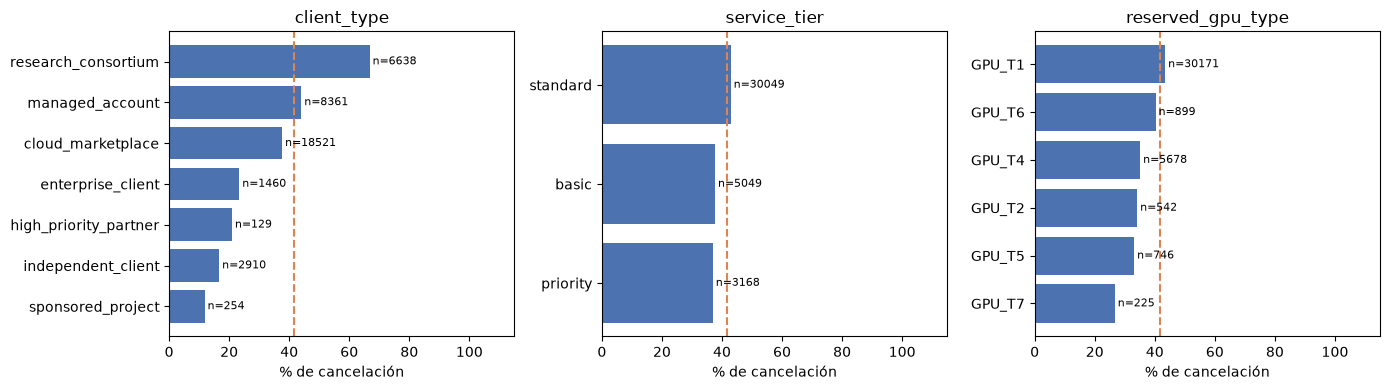

In [39]:
# ANÁLISIS POR COHORTES

cols_cohortes = ["client_type", "service_tier", "reserved_gpu_type"]

for col in cols_cohortes:

    tabla = train.groupby(col).agg(
        reservas=("canceled_job", "size"),
        tasa_cancelacion=("canceled_job", "mean"),
    )
    # El peso de la cohorte importa tanto como su tasa
    tabla["porc_del_train"] = tabla["reservas"] / len(train) * 100

    print(f"\n=== {col} ===")
    print(tabla.sort_values("reservas", ascending=False).round(3))

# Gráfico: tasa de cancelación de cada cohorte, con su tamaño al lado
fig, axes = plt.subplots(1, 3, figsize=(14, 4))

for ax, col in zip(axes, cols_cohortes):

    tabla = train.groupby(col).agg(
        reservas=("canceled_job", "size"),
        tasa=("canceled_job", "mean"),
    )
    # Solo cohortes con suficientes casos como para que la tasa sea confiable
    tabla = tabla[tabla["reservas"] >= minimo_reservas].sort_values("tasa")

    ax.barh(tabla.index, tabla["tasa"] * 100, color="#4C72B0")

    # Cantidad de reservas al lado de cada barra
    for i, (t, n) in enumerate(zip(tabla["tasa"], tabla["reservas"])):
        ax.text(t * 100 + 1, i, f"n={n}", va="center", fontsize=8)

    # Línea de referencia con la tasa global
    ax.axvline(train["canceled_job"].mean() * 100, color="#DD8452", linestyle="--")

    ax.set_xlim(0, 115)
    ax.set_xlabel("% de cancelación")
    ax.set_title(col)

plt.tight_layout()
plt.show()

La línea naranja marca la tasa global de cancelación del train (41,7%).

- **`client_type`** es la cohorte más útil de las tres. `cloud_marketplace` concentra el **48,4%** de las reservas y cancela por debajo del promedio (37,6%), mientras que `research_consortium` es el **17,3%** del train y cancela el **66,8%**. Son dos poblaciones con comportamientos muy distintos.
- **`service_tier`** casi no discrimina: `standard` (78,5% de las reservas) cancela 42,9% y `priority` 36,9%. La diferencia es chica comparada con las otras cohortes.
- **`reserved_gpu_type`** está muy concentrada: `GPU_T1` es el **78,8%** del train. El resto de los tipos tienen tasas entre 26,7% y 40,3%, pero cada uno representa pocos casos.

Las cohortes `unknown` en `client_type` (1 reserva), `enterprise` en `service_tier` (8) y `GPU_T12` / `GPU_T3` en `reserved_gpu_type` (5 y 8) tienen demasiado pocos casos para sacar conclusiones. Se agruparán en "otros" durante el preprocesamiento.

### 4.4 Outliers y valores atípicos

Siguiendo el criterio del rango intercuartílico (IQR), se consideran atípicos los valores por encima de `Q3 + 1,5 × IQR`.

                          mediana  maximo  limite_IQR  n_atipicos
variable                                                         
hours_before_execution      71.00   629.0      360.50        1363
estimated_cost_per_hour      4.97   270.0        9.75        1072
queue_wait_time              0.00   391.0        0.00        1743
num_background_processes     0.00    10.0        0.00         173


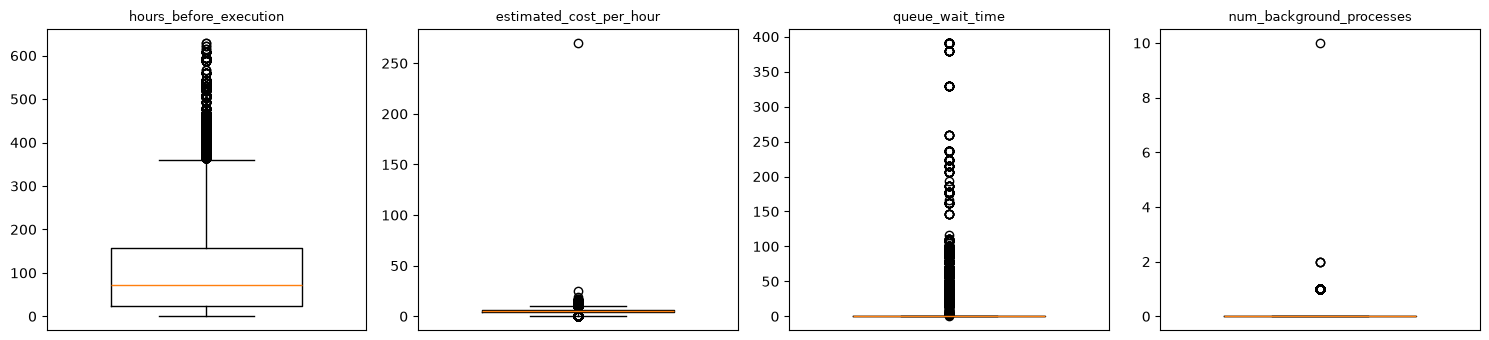


num_background_processes:
num_background_processes
0     38101
1       169
2         3
10        1
Name: count, dtype: int64

estimated_cost_per_hour:
  reservas con costo 0: 601
  reservas con costo mayor a 100: 1


In [40]:
# OUTLIERS: CRITERIO DEL RANGO INTERCUARTÍLICO (IQR)

cols_revisar = [
    "hours_before_execution",
    "estimated_cost_per_hour",
    "queue_wait_time",
    "num_background_processes",
]

filas_iqr = []

for col in cols_revisar:

    q1 = train[col].quantile(0.25)
    q3 = train[col].quantile(0.75)
    iqr = q3 - q1

    # Todo lo que supere este límite se considera atípico
    limite_superior = q3 + 1.5 * iqr

    filas_iqr.append({
        "variable": col,
        "mediana": train[col].median(),
        "maximo": train[col].max(),
        "limite_IQR": limite_superior,
        "n_atipicos": int((train[col] > limite_superior).sum()),
    })

print(pd.DataFrame(filas_iqr).set_index("variable").round(2))

# Boxplots para ver la forma de cada distribución
fig, axes = plt.subplots(1, len(cols_revisar), figsize=(15, 3.5))

for ax, col in zip(axes, cols_revisar):
    ax.boxplot(train[col].dropna(), widths=0.6)
    ax.set_title(col, fontsize=9)
    ax.set_xticks([])

plt.tight_layout()
plt.show()

# Miramos de cerca los dos casos sospechosos de ser errores de carga
print("\nnum_background_processes:")
print(train["num_background_processes"].value_counts().sort_index())

print("\nestimated_cost_per_hour:")
print("  reservas con costo 0:", (train["estimated_cost_per_hour"] == 0).sum())
print("  reservas con costo mayor a 100:", (train["estimated_cost_per_hour"] > 100).sum())

Conviene distinguir dos situaciones distintas:

**Valores extremos pero plausibles.** `hours_before_execution` llega a 629 horas: son reservas hechas con mucha anticipación, pero perfectamente posibles. `queue_wait_time` tiene mediana 0, así que el criterio IQR marca como atípica cualquier espera mayor a cero, lo cual no tiene sentido tratar como error. En estos casos **no se eliminan filas**: son parte de la variabilidad real del problema.

**Valores sospechosos de ser errores de carga.** Acá sí aparecen dos casos concretos:

- **`num_background_processes`**: 38.101 reservas tienen 0, 169 tienen 1 y 3 tienen 2. Y aparece **una sola reserva con 10**. Un salto de 2 a 10 con un único caso no parece un valor real.
- **`estimated_cost_per_hour`**: la mediana es 4,97 USD y hay **una sola reserva con 270**, más de 50 veces la mediana. Además hay **601 reservas con costo 0**, que podrían ser cortesías o errores de registro.

Son muy pocos casos (menos del 1,6% del train) y los modelos basados en árboles son robustos a valores extremos, así que **no se eliminan**. Quedan identificados por si el análisis de errores más adelante los señala como problemáticos.

### 4.5 Variables con información posterior a la reserva

En la sección 1 se eliminaron `execution_status` y `execution_status_date` por contener el resultado de la reserva. Queda una variable con un problema parecido pero más sutil: **`assigned_gpu_type`**, el tipo de GPU finalmente asignado.

In [41]:
# ¿assigned_gpu_type APORTA INFORMACIÓN POSTERIOR A LA RESERVA?

# Marcamos si la GPU asignada es distinta de la que se había reservado
gpu_cambiada = train["assigned_gpu_type"] != train["reserved_gpu_type"]

tabla_gpu = train.groupby(gpu_cambiada).agg(
    reservas=("canceled_job", "size"),
    tasa_cancelacion=("canceled_job", "mean"),
)
tabla_gpu.index = ["Misma GPU que la reservada", "Le cambiaron la GPU"]

print(tabla_gpu.round(3))

                            reservas  tasa_cancelacion
Misma GPU que la reservada     34777             0.453
Le cambiaron la GPU             3497             0.064


El resultado es contundente: cuando la GPU asignada difiere de la reservada (3.497 reservas, el 9,1% del train), la tasa de cancelación baja al **6,4%**, frente al **45,3%** cuando no hubo cambio.

La explicación es que **una reserva solo se reasigna a otra GPU si efectivamente va a ejecutarse**. Es decir, que la GPU haya cambiado es consecuencia de que la reserva no se canceló, no una causa de ello. Es el mismo mecanismo que `execution_status`, pero en versión probabilística en lugar de determinista.

Se decide **conservarla**, por dos motivos:

1. La cátedra la incluye en el conjunto de evaluación: el enunciado del leaderboard aclara que la entrada viene sin `canceled_job`, `execution_status` ni `execution_status_date`, pero no excluye `assigned_gpu_type`.
2. Su impacto se medirá explícitamente en la etapa de optimización, entrenando con y sin ella.

### 4.6 Conclusiones del análisis exploratorio

| Hallazgo | Implicancia |
|---|---|
| `reservation_commitment = locked_allocation` cancela el 99,8% | Variable muy predictiva, pero conocida al reservar: se conserva |
| `hours_before_execution` y `special_resource_requests` son las numéricas más informativas | Candidatas a transformaciones o combinaciones |
| `client_type` separa fuerte (66,8% vs 11,8%); `service_tier` casi no separa | `client_type` es la cohorte útil para el análisis de errores |
| Variables temporales con correlación casi nula | Se conservan: los árboles pueden aprovecharlas de forma no lineal |
| Pocos outliers y en su mayoría plausibles | No se eliminan filas |
| `assigned_gpu_type` contiene información posterior a la reserva | Se conserva y se mide su impacto por separado |

## 5. Preprocesamiento

Las transformaciones se arman dentro de un **`Pipeline` de scikit-learn** en lugar de aplicarlas directamente sobre el DataFrame. Esto tiene tres ventajas:

- Los parámetros de cada transformación (la mediana para imputar, la media y el desvío para escalar, las categorías conocidas) se calculan **solo con train** y se aplican tal cual a validación y test. Así se evita el data leakage.
- El mismo objeto se puede aplicar a datos nuevos sin repetir código, que es exactamente lo que necesita la función predictora de la etapa final.
- Las transformaciones quedan dentro de la validación cruzada, así que cada fold se preprocesa con sus propios datos de entrenamiento.

### 5.1 Grupos de columnas

Las columnas se separan en tres grupos, porque cada uno necesita un tratamiento distinto. Las variables redundantes ya se eliminaron en la sección 4.1.

In [42]:
# GRUPOS DE COLUMNAS SEGÚN SU TRATAMIENTO

# Identificadores: pandas los lee como números, pero son etiquetas.
# Además concentran casi todos los valores faltantes del dataset.
cols_identificadores = ["orchestration_agent_id", "organization_id"]

# Nominales: las categóricas de texto, definidas en la sección 2.4
cols_nominales = list(cols_categoricas)

# Numéricas: todo lo que no entra en los grupos anteriores
cols_numericas = [c for c in X_train.columns
                  if c not in cols_identificadores + cols_nominales]

resumen_grupos = pd.DataFrame({
    "grupo": ["Numéricas", "Nominales", "Identificadores"],
    "columnas": [len(cols_numericas), len(cols_nominales),
                 len(cols_identificadores)],
})

print(resumen_grupos.to_string(index=False))

print("\nNuméricas:", cols_numericas)
print("\nNominales:", cols_nominales)

          grupo  columnas
      Numéricas        18
      Nominales         8
Identificadores         2

Numéricas: ['hours_before_execution', 'execution_year', 'execution_month', 'execution_day', 'peak_gpu_hours', 'offpeak_gpu_hours', 'num_primary_processes', 'num_auxiliary_processes', 'num_background_processes', 'returning_client', 'previous_job_cancellations', 'successful_previous_jobs', 'resource_modifications', 'queue_wait_time', 'estimated_cost_per_hour', 'reserved_storage_units', 'special_resource_requests', 'high_value_client']

Nominales: ['service_tier', 'client_type', 'request_channel', 'reserved_gpu_type', 'assigned_gpu_type', 'reservation_commitment', 'workload_profile', 'client_region']


### 5.2 Construcción del pipeline

Cada grupo recibe su propio tratamiento:

| Grupo | Valores faltantes | Transformación |
|---|---|---|
| Numéricas | Mediana (robusta a los valores extremos de la sección 4.4) | `StandardScaler` |
| Nominales | Categoría más frecuente | `OneHotEncoder` |
| Identificadores | Constante `-1`, que representa "sin agente" / "sin organización" | `OneHotEncoder` |

Dos decisiones del `OneHotEncoder` merecen explicación:

- **`min_frequency=0.01`** agrupa automáticamente en una sola columna todas las categorías que representan menos del 1% de los datos. Es la agrupación en "otros" que se anticipó en la sección 2.4, y resuelve el problema de los 149 países de `client_region` y de los 194 agentes de orquestación.
- **`handle_unknown="infrequent_if_exist"`** hace que una categoría nunca vista en entrenamiento se trate como una categoría poco frecuente más, en lugar de producir un error. Sin esto, la función predictora fallaría si en el conjunto de evaluación apareciera un país que no está en train.

El escalado no es necesario para los modelos basados en árboles, pero sí para la regresión logística y los métodos basados en distancias. Se incluye para poder comparar todas las familias de clasificadores con el mismo pipeline.

In [43]:
# PIPELINE DE PREPROCESAMIENTO

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

pipe_numericas = Pipeline([
    ("imputar", SimpleImputer(strategy="median")),
    ("escalar", StandardScaler()),
])

pipe_nominales = Pipeline([
    ("imputar", SimpleImputer(strategy="most_frequent")),
    ("codificar", OneHotEncoder(handle_unknown="infrequent_if_exist",
                                min_frequency=0.01,
                                sparse_output=False)),
])

pipe_identificadores = Pipeline([
    # El -1 representa "sin agente" / "sin organización"
    ("imputar", SimpleImputer(strategy="constant", fill_value=-1)),
    ("codificar", OneHotEncoder(handle_unknown="infrequent_if_exist",
                                min_frequency=0.01,
                                sparse_output=False)),
])

# remainder="drop" descarta cualquier columna que no esté en los grupos anteriores
preprocesador = ColumnTransformer([
    ("numericas", pipe_numericas, cols_numericas),
    ("nominales", pipe_nominales, cols_nominales),
    ("identificadores", pipe_identificadores, cols_identificadores),
], remainder="drop")

# Lo ajustamos SOLO con train
X_train_pre = preprocesador.fit_transform(X_train)

print("X_train:", X_train.shape, "->", X_train_pre.shape)
print("Valores faltantes después de preprocesar:", int(np.isnan(X_train_pre).sum()))

# Cuántas columnas generó cada variable de alta cardinalidad
nombres_columnas = preprocesador.get_feature_names_out()

print("\nColumnas generadas por las variables de alta cardinalidad:")
for col in ["client_region", "orchestration_agent_id", "organization_id"]:
    print(f"  {col}: {sum(col in n for n in nombres_columnas)} columnas")

X_train: (38274, 28) -> (38274, 83)
Valores faltantes después de preprocesar: 0

Columnas generadas por las variables de alta cardinalidad:
  client_region: 15 columnas
  orchestration_agent_id: 14 columnas
  organization_id: 3 columnas


El pipeline transforma las **28 columnas** originales en **83 columnas** numéricas, sin valores faltantes. La agrupación de categorías poco frecuentes reduce `client_region` de 149 países a 15 columnas y los 194 agentes de orquestación a 14, evitando que la dimensionalidad explote.

Dos aclaraciones sobre cómo se usa de acá en adelante:

- El `preprocesador` se ajustó con train **solo para verificar que funciona**. En la validación cruzada no se usará este objeto ya ajustado: se lo encadenará con cada clasificador dentro de un `Pipeline` completo, de modo que en cada fold se reajuste únicamente con los datos de entrenamiento de ese fold.
- `X_test` todavía no se tocó. Se transformará recién en la evaluación final.

Con esto queda cerrada la etapa de preprocesamiento y análisis exploratorio. El siguiente paso es entrenar los primeros clasificadores y establecer un baseline.